<a href="https://colab.research.google.com/github/lekhasree15/BIS_LAB/blob/main/lab2_AND_lab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ECONOMIC DISPATCH RESULTS
-------------------------
Generator 1: 200.00 MW
Generator 2: 190.62 MW
Generator 3: 59.38 MW

Total generation: 450.00 MW
Power demand:     450.00 MW
Total fuel cost:  1799.22 cost units/hour


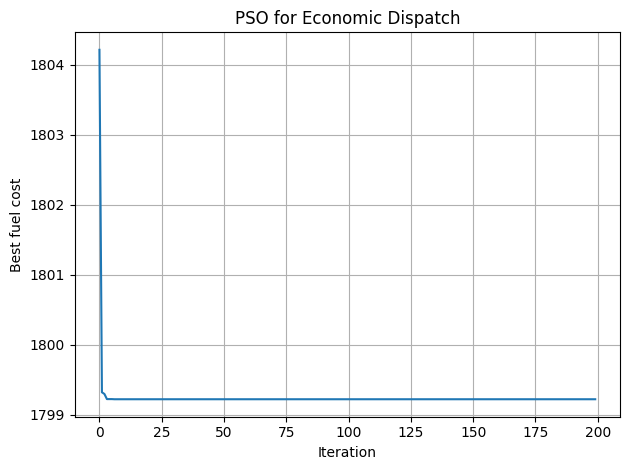

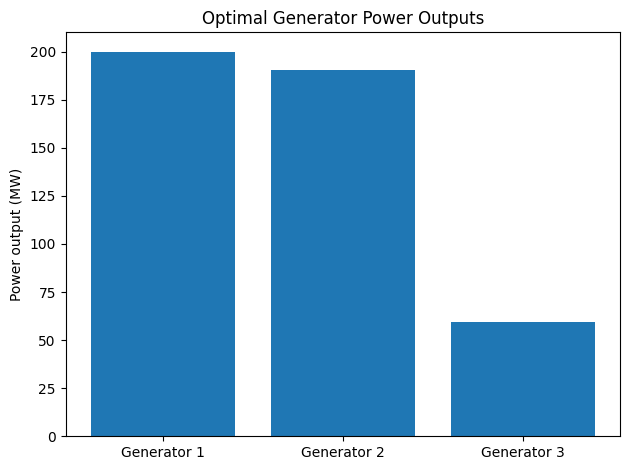

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Generator data
# Fuel cost: F(P) = a*P^2 + b*P + c
a = np.array([0.00375, 0.0175, 0.0625])
b = np.array([2.0, 1.75, 1.0])
c = np.array([0.0, 0.0, 0.0])

Pmin = np.array([50.0, 50.0, 50.0])    # Minimum MW
Pmax = np.array([200.0, 200.0, 300.0]) # Maximum MW
demand = 450.0                         # Required power in MW

# 2. PSO parameters
n_particles = 40
iterations = 200
w = 0.7       # Inertia weight
c1 = 1.5      # Cognitive coefficient
c2 = 1.5      # Social coefficient

np.random.seed(42)
n_gen = len(a)


# 3. Repair particle to satisfy power demand
def repair(position):
    # Project outputs onto generator limits while
    # ensuring total generation equals demand.
    low = np.min(Pmin - position)
    high = np.max(Pmax - position)

    for _ in range(100):
        mid = (low + high) / 2
        power = np.clip(position + mid, Pmin, Pmax)

        if power.sum() < demand:
            low = mid
        else:
            high = mid

    return np.clip(position + (low + high) / 2,
                   Pmin, Pmax)


# 4. Calculate total fuel cost
def fitness(position):
    return np.sum(a * position**2 + b * position + c)


# 5. Initialize particles and velocities
positions = np.random.uniform(
    Pmin, Pmax, (n_particles, n_gen)
)

for i in range(n_particles):
    positions[i] = repair(positions[i])

velocities = np.zeros_like(positions)

pbest = positions.copy()
pbest_cost = np.array([fitness(p) for p in positions])

best_index = np.argmin(pbest_cost)
gbest = pbest[best_index].copy()
gbest_cost = pbest_cost[best_index]

history = []

# 6. PSO optimization loop
for iteration in range(iterations):
    r1 = np.random.rand(n_particles, n_gen)
    r2 = np.random.rand(n_particles, n_gen)

    velocities = (
        w * velocities
        + c1 * r1 * (pbest - positions)
        + c2 * r2 * (gbest - positions)
    )

    positions += velocities

    # Enforce generator limits and power balance
    for i in range(n_particles):
        positions[i] = repair(
            np.clip(positions[i], Pmin, Pmax)
        )

    costs = np.array([fitness(p) for p in positions])

    # Update personal best
    improved = costs < pbest_cost
    pbest[improved] = positions[improved]
    pbest_cost[improved] = costs[improved]

    # Update global best
    best_index = np.argmin(pbest_cost)

    if pbest_cost[best_index] < gbest_cost:
        gbest = pbest[best_index].copy()
        gbest_cost = pbest_cost[best_index]

    history.append(gbest_cost)

# 7. Display results
print("ECONOMIC DISPATCH RESULTS")
print("-------------------------")

for i, power in enumerate(gbest):
    print(f"Generator {i+1}: {power:.2f} MW")

print(f"\nTotal generation: {gbest.sum():.2f} MW")
print(f"Power demand:     {demand:.2f} MW")
print(f"Total fuel cost:  {gbest_cost:.2f} cost units/hour")

# 8. Plot convergence
plt.plot(history)
plt.xlabel("Iteration")
plt.ylabel("Best fuel cost")
plt.title("PSO for Economic Dispatch")
plt.grid(True)
plt.tight_layout()
plt.show()

# 9. Plot generator outputs
plt.bar(["Generator 1", "Generator 2", "Generator 3"], gbest)
plt.ylabel("Power output (MW)")
plt.title("Optimal Generator Power Outputs")
plt.tight_layout()
plt.show()

Iteration 10: Best distance = 197.41
Iteration 20: Best distance = 197.41
Iteration 30: Best distance = 197.41
Iteration 40: Best distance = 197.41
Iteration 50: Best distance = 197.41
Iteration 60: Best distance = 197.41
Iteration 70: Best distance = 197.41
Iteration 80: Best distance = 197.41
Iteration 90: Best distance = 197.41
Iteration 100: Best distance = 197.41

Best tour: [5, 7, 6, 4, 3, 1, 0, 2, 5]
Shortest distance: 197.41


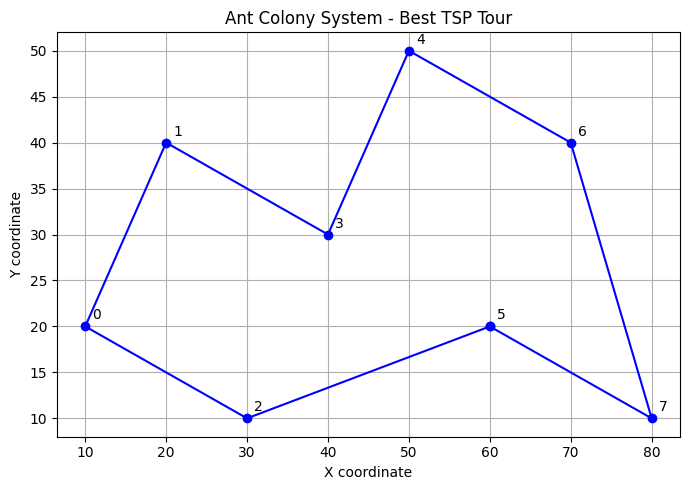

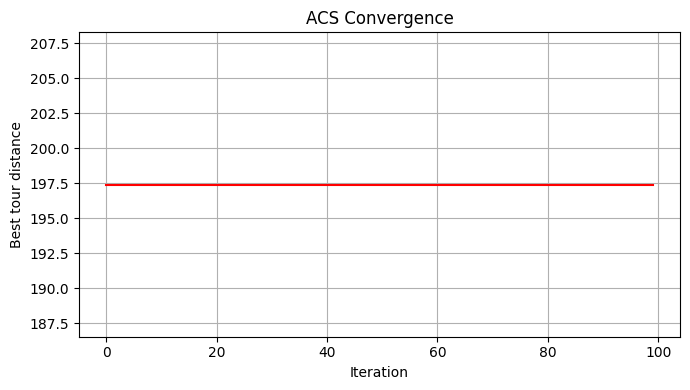

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Define cities using (x, y) coordinates
cities = np.array([
    [10, 20], [20, 40], [30, 10], [40, 30],
    [50, 50], [60, 20], [70, 40], [80, 10]
])

n = len(cities)

# 2. Calculate distances between cities
dist = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        dist[i, j] = np.linalg.norm(cities[i] - cities[j])

# 3. Initialize ACS parameters
ants = 10
iterations = 100
alpha = 1.0
beta = 2.0
rho = 0.1
q0 = 0.9
xi = 0.1
Q = 1.0

pheromone = np.ones((n, n)) * 0.1
heuristic = 1 / (dist + np.eye(n) * 1e10 + 1e-10)

best_path = None
best_length = float("inf")
history = []

np.random.seed(42)

# 4. Run Ant Colony System
for iteration in range(iterations):
    all_paths = []
    all_lengths = []

    for ant in range(ants):
        start = np.random.randint(n)
        path = [start]
        unvisited = set(range(n))
        unvisited.remove(start)
        current = start

        while unvisited:
            candidates = list(unvisited)

            weights = np.array([
                (pheromone[current, j] ** alpha)
                * (heuristic[current, j] ** beta)
                for j in candidates
            ])

            probabilities = weights / weights.sum()

            # ACS pseudorandom proportional rule
            if np.random.rand() < q0:
                next_city = candidates[np.argmax(weights)]
            else:
                next_city = np.random.choice(
                    candidates, p=probabilities
                )

            # Local pheromone update
            pheromone[current, next_city] = (
                (1 - xi) * pheromone[current, next_city]
                + xi * 0.1
            )
            pheromone[next_city, current] = pheromone[current, next_city]

            path.append(next_city)
            unvisited.remove(next_city)
            current = next_city

        # Return to starting city
        path.append(start)

        length = sum(
            dist[path[i], path[i + 1]]
            for i in range(len(path) - 1)
        )

        all_paths.append(path)
        all_lengths.append(length)

        if length < best_length:
            best_length = length
            best_path = path.copy()

    # Global pheromone update on best-so-far tour
    pheromone *= (1 - rho)

    for i in range(len(best_path) - 1):
        a, b = best_path[i], best_path[i + 1]
        pheromone[a, b] += rho * Q / best_length
        pheromone[b, a] = pheromone[a, b]

    history.append(best_length)

    if (iteration + 1) % 10 == 0:
        print(
            f"Iteration {iteration + 1}: "
            f"Best distance = {best_length:.2f}"
        )

# 5. Display results
print("\nBest tour:", best_path)
print("Shortest distance:", round(best_length, 2))

# 6. Plot the best route
route = cities[best_path]

plt.figure(figsize=(7, 5))
plt.plot(route[:, 0], route[:, 1], "o-", color="blue")
for i, (x, y) in enumerate(cities):
    plt.annotate(str(i), (x, y), xytext=(5, 5),
                 textcoords="offset points")
plt.title("Ant Colony System - Best TSP Tour")
plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.grid(True)
plt.tight_layout()
plt.show()

# 7. Plot convergence
plt.figure(figsize=(7, 4))
plt.plot(history, color="red")
plt.title("ACS Convergence")
plt.xlabel("Iteration")
plt.ylabel("Best tour distance")
plt.grid(True)
plt.tight_layout()
plt.show()